# Лабораторная работа 2. Исследовательский анализ данных

**Цель работы:** изучение связи между признаками двумерного набора данных, визуализация данных.

### Описание предметной области

**Вариант №5**

**Набор данных:** `visits.csv` — данные пользовательских сессий интернет-магазина.

**Атрибуты:**
1. `user_id` – уникальный идентификатор пользователя, тип `int64`;
2. `region` – страна пользователя, тип `object`;
3. `device` – устройство пользователя, тип `object`;
4. `channel` – идентификатор рекламного источника, из которого пришёл пользователь (`organic` – переход без рекламы), тип `object`;
5. `session_start` – дата и время начала сессии, исходный тип `object`;
6. `session_end` – дата и время окончания сессии, исходный тип `object`;
7. `time_session` – время сессии в минутах, исходный тип `float64`;
8. `click_count` – количество кликов пользователя, исходный тип `float64`;
9. `buy_count` – количество товаров в корзине, исходный тип `float64`;
10. `price` – стоимость покупок, исходный тип `float64`;
11. `age` – возраст пользователя, тип `int64`.

**Единица наблюдения** – одна пользовательская сессия. Один пользователь мог заходить в магазин несколько раз, поэтому в работе под «клиентом» (количество клиентов) понимается запись о сессии, а «уникальные пользователи» считаются отдельно по `user_id`.

**План работы:** загрузка и предобработка → матрица диаграмм рассеяния → гистограммы → ковариация и корреляция → графики по заданию варианта → hexbin → boxplot (по столбцу, по созданной категории, по другим категориям) → общие выводы.

### 1. Загрузка набора данных и предварительная обработка

#### 1.1 Импорт библиотек и чтение файла

Файл использует разделитель `;`, поэтому он передаётся в `read_csv` параметром `sep`. 

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')   # единый стиль графиков

df = pd.read_csv('visits.csv', sep=';')

#### 1.2 Первичный обзор: head, info, describe

Весь блок обрабатывается строго аналогично тому, как это происходило в первой лабораторной работе. Исправляются те же ошибки и так далее.

In [10]:
df.head(10)

,user_id,region,device,channel,session_start,session_end,time_session,click_count,buy_count,price,age
0,278965908054,United States,iPhone,organic,01.05.2019 4:46,01.05.2019 4:47,1.0,0.0,0.0,0.0,31
1,244878945432,United States,Mac,organic,01.05.2019 16:44,01.05.2019 16:45,1.0,0.0,0.0,0.0,40
2,590706206550,United States,Mac,organic,01.05.2019 14:09,01.05.2019 15:32,83.0,28.0,6.0,14570.0,50
3,326433527971,United States,Android,TipTop,01.05.2019 0:29,01.05.2019 0:54,25.0,8.0,3.0,4411.0,38
4,349773784594,United States,Mac,organic,01.05.2019 3:33,01.05.2019 3:57,24.0,8.0,3.0,4411.0,63
5,90242400005,United States,Android,organic,01.05.2019 9:03,01.05.2019 10:08,65.0,22.0,4.0,11310.0,62
6,43958116050,United States,iPhone,organic,01.05.2019 9:37,01.05.2019 10:00,23.0,8.0,3.0,4411.0,60
7,15174034813,United States,Mac,organic,01.05.2019 13:33,01.05.2019 13:35,2.0,0.0,0.0,0.0,12
8,446013509831,United States,iPhone,organic,01.05.2019 14:44,01.05.2019 15:41,57.0,19.0,4.0,9872.0,52
9,100970711362,United States,Mac,FaceBoom,01.05.2019 6:20,01.05.2019 6:54,34.0,12.0,3.0,6326.0,25


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 954 entries, 0 to 953
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   user_id        954 non-null    int64  
 1   region         953 non-null    str    
 2   device         953 non-null    str    
 3   channel        954 non-null    str    
 4   session_start  954 non-null    str    
 5   session_end    954 non-null    str    
 6   time_session   954 non-null    float64
 7   click_count    954 non-null    float64
 8   buy_count      954 non-null    float64
 9   price          954 non-null    float64
 10  age            954 non-null    int64  
dtypes: float64(4), int64(2), str(5)
memory usage: 82.1 KB


Набор данных содержит **954 записи и 11 столбцов**. Заметны следующие проблемы:
- в столбцах `region` и `device` по одному пропуску (по 953 непустых значения из 954);
- даты `session_start` и `session_end` имеют тип `object` (строки), их нужно перевести в `datetime`;
- `time_session`, `click_count`, `buy_count` и `price` загружены как `float64`, хотя по смыслу это целые числа.

In [12]:
df.describe()

,user_id,time_session,click_count,buy_count,price,age
count,9.540000e+02,954.000000,954.000000,954.000000,954.000000,954.000000
mean,4.951807e+11,29.062893,9.830189,2.527254,5341.559748,39.810273
std,2.899488e+11,27.134816,9.209039,1.602003,5060.247685,13.038029
min,2.346325e+09,0.000000,0.000000,0.000000,0.000000,10.000000
25%,2.295122e+11,9.000000,3.000000,2.000000,2301.000000,29.000000
50%,4.984267e+11,21.000000,7.000000,2.000000,3739.000000,39.000000
75%,7.525332e+11,42.000000,14.000000,3.000000,7284.000000,50.000000
max,9.985130e+11,262.000000,88.000000,15.000000,56546.000000,71.000000


`describe` показывает следующее (столбец `user_id` – идентификатор, его среднее и квартили смысла не имеют):

- **time_session**: среднее ≈ 29 мин, медиана 21 мин, максимум 262 мин. Среднее заметно больше медианы, поэтому распределение скошено вправо – есть небольшое число очень длинных сессий. Минимум 0 – «пустые» сессии.
- **click_count**: среднее ≈ 9.8, медиана 7, максимум 88 – картина аналогична длительности.
- **buy_count**: среднее ≈ 2.5, медиана 2, максимум 15.
- **price**: среднее ≈ 5342, медиана 3739, максимум 56 546; 25% значений не превышают 2301, а максимум почти в 8 раз больше 75-го процентиля (7284), т.е. есть единичные очень дорогие сессии. Минимум 0 – сессии без покупок.
- **age**: среднее ≈ 39.8, медиана 39, диапазон 10–71 год; среднее и медиана почти совпадают – распределение близко к симметричному.

#### 1.3 Предварительная обработка данных

**а) Названия столбцов.** Проверим названия на лишние пробелы.

In [13]:
print(df.columns.tolist())

['user_id ', 'region', 'device', 'channel', 'session_start', 'session_end', 'time_session', 'click_count', 'buy_count', 'price', 'age']


У первого столбца в конце имени есть лишний пробел (`'user_id '`) – из-за него обращение `df['user_id']` вызвало бы ошибку. Удаляем пробелы методом `str.strip()`.

In [14]:
df.columns = df.columns.str.strip()
print(df.columns.tolist())

['user_id', 'region', 'device', 'channel', 'session_start', 'session_end', 'time_session', 'click_count', 'buy_count', 'price', 'age']


**б) Пропуски.** Найдём строки с пропусками.

In [15]:
print(df.isna().sum())
df[df.isna().any(axis=1)]

user_id          0
region           1
device           1
channel          0
session_start    0
session_end      0
time_session     0
click_count      0
buy_count        0
price            0
age              0
dtype: int64


,user_id,region,device,channel,session_start,session_end,time_session,click_count,buy_count,price,age
33,750734101231,NaN,iPhone,MediaTornado,01.05.2019 7:57,01.05.2019 8:22,25.0,8.0,3.0,4411.0,54
802,141837741427,United States,NaN,MediaTornado,01.05.2019 1:59,01.05.2019 2:21,22.0,7.0,2.0,3739.0,34


Пропущены `region` в одной записи и `device` в другой. Это 2 записи из 954 (≈0.2%), восстановить значения по другим признакам нельзя, а заполнение модой исказило бы категориальные данные, поэтому такие строки удаляем.

In [16]:
df = df.dropna()
print('Размер таблицы:', df.shape)
print('Пропусков осталось:', df.isna().sum().sum())

Размер таблицы: (952, 11)
Пропусков осталось: 0


**в) Дубликаты.** Сначала проверим явные дубликаты, затем неявные – разные написания одной и той же категории.

In [17]:
print('Явных дубликатов:', df.duplicated().sum())
print()
for col in ['region', 'device', 'channel']:
    print(col, df[col].value_counts().to_dict())

Явных дубликатов: 0

region {'United States': 899, 'Russia': 52, 'USA': 1}
device {'iPhone': 418, 'Mac': 243, 'Android': 185, 'PC': 103, 'IPHONE': 2, 'MAC': 1}
channel {'organic': 610, 'FaceBoom': 149, 'TipTop': 142, 'MediaTornado': 51}


Явных дубликатов нет. Среди категорий есть **неявные дубликаты**: `USA` и `United States` (страна), `MAC` и `Mac`, `IPHONE` и `iPhone` (устройство). Приводим их к единому написанию. Для страны выбрано `United States`, т.к. именно так подписаны данные в большинстве записей.

In [18]:
df['region'] = df['region'].replace('USA', 'United States')
df['device'] = df['device'].replace({'MAC': 'Mac', 'IPHONE': 'iPhone'})

for col in ['region', 'device', 'channel']:
    print(col, df[col].value_counts().to_dict())
print('Явных дубликатов после унификации:', df.duplicated().sum())

region {'United States': 900, 'Russia': 52}
device {'iPhone': 420, 'Mac': 244, 'Android': 185, 'PC': 103}
channel {'organic': 610, 'FaceBoom': 149, 'TipTop': 142, 'MediaTornado': 51}
Явных дубликатов после унификации: 0


**г) Типы данных.** Проверим, что в `float`-столбцах действительно только целые числа, и приведём их к `int64`.

In [19]:
int_cols = ['time_session', 'click_count', 'buy_count', 'price']
print((df[int_cols] % 1 == 0).all())
df[int_cols] = df[int_cols].astype('int64')

time_session    True
click_count     True
buy_count       True
price           True
dtype: bool


Даты записаны в формате «день.месяц.год часы:минуты» (например, `01.05.2019 4:46`). Чтобы pandas не перепутал день и месяц, формат указываем явно. После преобразования проверим правильность: разность `session_end - session_start` должна совпадать со столбцом `time_session`.

In [20]:
for col in ['session_start', 'session_end']:
    df[col] = pd.to_datetime(df[col], format='%d.%m.%Y %H:%M')

print('Период данных:', df['session_start'].min(), '-', df['session_start'].max())

duration = (df['session_end'] - df['session_start']).dt.total_seconds() / 60
print('Расхождений между time_session и разностью дат:', (duration != df['time_session']).sum())

Период данных: 2019-05-01 00:06:00 - 2019-05-04 23:46:00
Расхождений между time_session и разностью дат: 0


Расхождений нет – даты разобраны верно. Важный вывод: **данные охватывают всего 4 дня (1–4 мая 2019 г.)**, поэтому анализировать сезонность или динамику по месяцам нельзя.

**д) Логические проверки и аномалии.** Проверим согласованность признаков и «подозрительные» значения.

In [21]:
print('Сессий с price == 0:', (df['price'] == 0).sum())
print('Сессий с buy_count == 0:', (df['buy_count'] == 0).sum())
print('Сессий, где одновременно price == 0 и buy_count == 0:', ((df['price'] == 0) & (df['buy_count'] == 0)).sum())
print('Сессий нулевой длительности:', (df['time_session'] == 0).sum())
print('Пользователей младше 18 лет (сессий):', (df['age'] < 18).sum(), '| минимальный возраст:', df['age'].min())
print('Уникальных user_id:', df['user_id'].nunique(), 'при', len(df), 'сессиях')

Сессий с price == 0: 103
Сессий с buy_count == 0: 103
Сессий, где одновременно price == 0 и buy_count == 0: 103
Сессий нулевой длительности: 10
Пользователей младше 18 лет (сессий): 37 | минимальный возраст: 10
Уникальных user_id: 782 при 952 сессиях


- `price == 0` в точности совпадает с `buy_count == 0` (103 сессии): стоимость нулевая тогда и только тогда, когда в корзине ничего нет – данные согласованы.
- 10 сессий нулевой длительности – это мгновенные заходы без действий; ошибкой не считаются, оставляем.
- Возраст от 10 лет встречается у 37 записей. Это возможное, хотя и редкое значение, поэтому такие записи сохраняем.
- В таблице 952 сессии и 782 уникальных пользователя: часть пользователей заходила повторно (170 пользователей – по 2 раза). Это нужно помнить при интерпретации: наблюдения не полностью независимы.

In [22]:
df.info()

<class 'pandas.DataFrame'>
Index: 952 entries, 0 to 953
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   user_id        952 non-null    int64         
 1   region         952 non-null    str           
 2   device         952 non-null    str           
 3   channel        952 non-null    str           
 4   session_start  952 non-null    datetime64[us]
 5   session_end    952 non-null    datetime64[us]
 6   time_session   952 non-null    int64         
 7   click_count    952 non-null    int64         
 8   buy_count      952 non-null    int64         
 9   price          952 non-null    int64         
 10  age            952 non-null    int64         
dtypes: datetime64[us](2), int64(6), str(3)
memory usage: 89.2 KB


После обработки получено **952 записи**, пропусков нет, категории унифицированы, числовые столбцы имеют тип `int64`, даты – `datetime64`. Набор готов к исследовательскому анализу.

### 2. Матрица диаграмм рассеяния

#### 2.1 Матрица диаграмм рассеяния для всех числовых признаков

В матрицу включены пять количественных признаков: `time_session`, `click_count`, `buy_count`, `price`, `age`. Исключены:
- `user_id` – идентификатор, а не измерение (его величина не несёт смысла);
- `session_start`, `session_end` – даты; их разность и есть `time_session`.

На диагонали показаны оценки плотности распределения каждого признака.

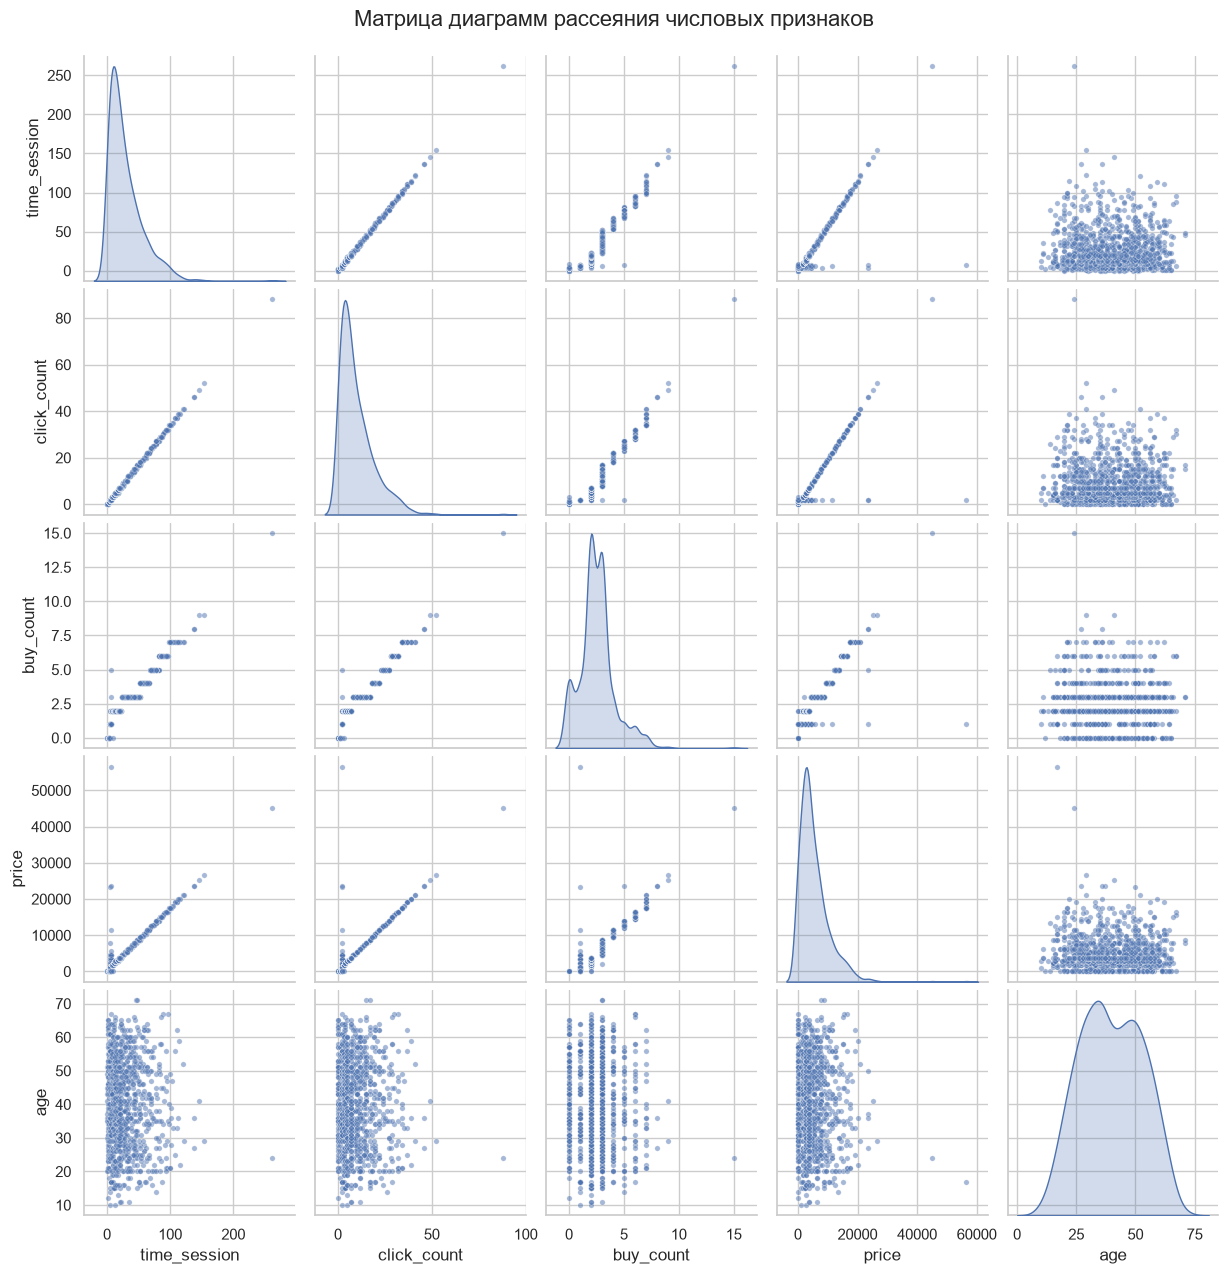

In [23]:
num_cols = ['time_session', 'click_count', 'buy_count', 'price', 'age']

g = sns.pairplot(df[num_cols], diag_kind='kde', plot_kws={'alpha': 0.5, 's': 15})
g.figure.suptitle('Матрица диаграмм рассеяния числовых признаков', y=1.02, fontsize=16)
plt.show()

**Анализ матрицы.** Матрица показывает определённую зависимость между переменными, но не между всеми:

- **`time_session` – `click_count`**: точки лежат практически на одной прямой – связь почти функциональная (в среднем один клик приходится на ≈3 минуты сессии).
- **`time_session` / `click_count` – `price`**: также близкая к линейной положительная зависимость – чем дольше сессия и больше кликов, тем выше стоимость покупок.
- **`buy_count` – остальные признаки**: положительная зависимость, имеющая вид «ступенек», т.к. `buy_count` принимает только целые значения.
- **`age` – любой другой признак**: облако точек без направления – возраст ни с чем линейно не связан.
- **Отклонения от общей картины.** Несколько точек заметно лежат выше прямой `time_session – price`: это короткие сессии (4–7 мин), в которых при всего 2 кликах стоимость покупок необычно велика (в т.ч. 56 546 при 7 минутах). Кроме того, в правом верхнем углу одиночная точка – самая длинная сессия (262 мин, 88 кликов, 15 покупок, 45 046): она ложится на общую линию, т.е. это крайнее, но не ошибочное значение.
- **Диагональ**: `time_session`, `click_count`, `price` скошены вправо (длинный правый «хвост»), `buy_count` имеет пик у 2–3 и отдельный пик в нуле, `age` близок к симметричному колоколообразному распределению.

#### 2.2 Диаграммы рассеяния по категориям

Построим зависимость стоимости покупок от длительности сессии с раскраской по устройству и по стране, а также зависимость стоимости от возраста с раскраской по каналу привлечения.

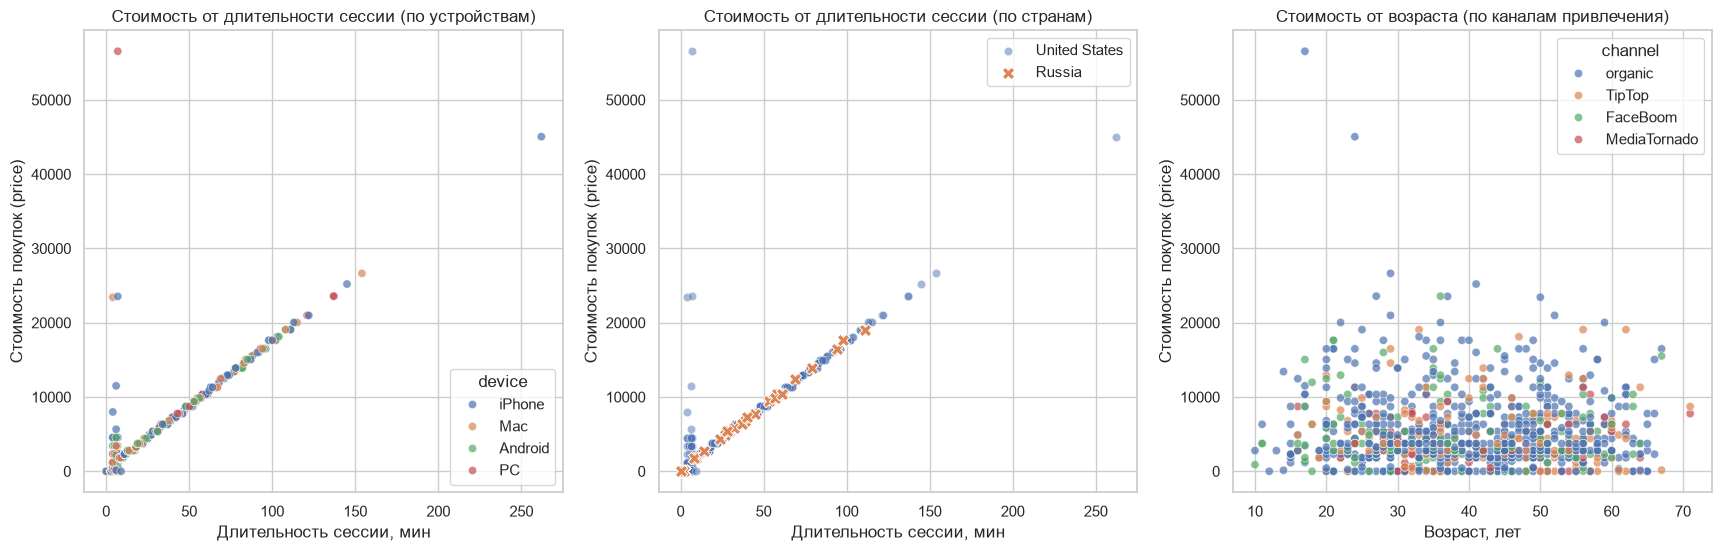

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

sns.scatterplot(data=df, x='time_session', y='price', hue='device', alpha=0.7, ax=axes[0])
axes[0].set_title('Стоимость от длительности сессии (по устройствам)')

us = df[df['region'] == 'United States']
ru = df[df['region'] == 'Russia']
sns.scatterplot(data=us, x='time_session', y='price', color='C0', alpha=0.5, label='United States', ax=axes[1])
sns.scatterplot(data=ru, x='time_session', y='price', color='C1', marker='X', s=80, label='Russia', ax=axes[1])
axes[1].set_title('Стоимость от длительности сессии (по странам)')

sns.scatterplot(data=df, x='age', y='price', hue='channel', alpha=0.7, ax=axes[2])
axes[2].set_title('Стоимость от возраста (по каналам привлечения)')

for ax in axes:
    ax.set_ylabel('Стоимость покупок (price)')
axes[0].set_xlabel('Длительность сессии, мин')
axes[1].set_xlabel('Длительность сессии, мин')
axes[2].set_xlabel('Возраст, лет')
plt.show()

- **По устройствам (слева):** точки всех четырёх устройств лежат на одной и той же линии. Зависимость стоимости от длительности не различается по устройствам – iPhone, Mac, Android и PC ведут себя одинаково; аномальная точка с ценой 56 546 относится к PC.
- **По странам (в центре):** сессии из России (крестики) лежат на той же прямой, что и американские, – зависимость стоимости от длительности в обеих странах одинакова. Заметная часть российских сессий сосредоточена в самом начале координат (почти нулевая длительность и нулевая стоимость), а аномальные точки выше прямой относятся только к США.
- **По каналам (справа):** облако «возраст – стоимость» не имеет формы ни для одного канала: пользователи любого возраста и любого канала встречаются на всех уровнях стоимости. Связи между возрастом и стоимостью нет.

### 3. Гистограммы числовых признаков

#### 3.1 Подбор количества интервалов (bins)

Число интервалов существенно влияет на вид гистограммы: слишком мало – теряются детали, слишком много – появляется шум. Для выбора сравним стандартные правила, реализованные в `numpy`: Стёрджеса (`sturges`), квадратного корня (`sqrt`), Скотта (`scott`) и Фридмана–Диакониса (`fd`).

In [25]:
rules = pd.DataFrame(
    {rule: [len(np.histogram_bin_edges(df[c], bins=rule)) - 1 for c in num_cols]
     for rule in ['sturges', 'sqrt', 'scott', 'fd']},
    index=num_cols
)
rules

,sturges,sqrt,scott,fd
time_session,11,31,28,40
click_count,11,31,27,40
buy_count,11,15,15,15
price,11,31,32,56
age,11,31,14,15


Правила дают разные результаты: Стёрджеса – 11 интервалов для всех признаков (при сильной скошенности это слишком грубо), Фридмана–Диакониса для скошенных признаков – 40–56 (получается шумно), а Скотт и квадратный корень – 27–32. Посмотрим на примере `time_session`, как меняется вид гистограммы.

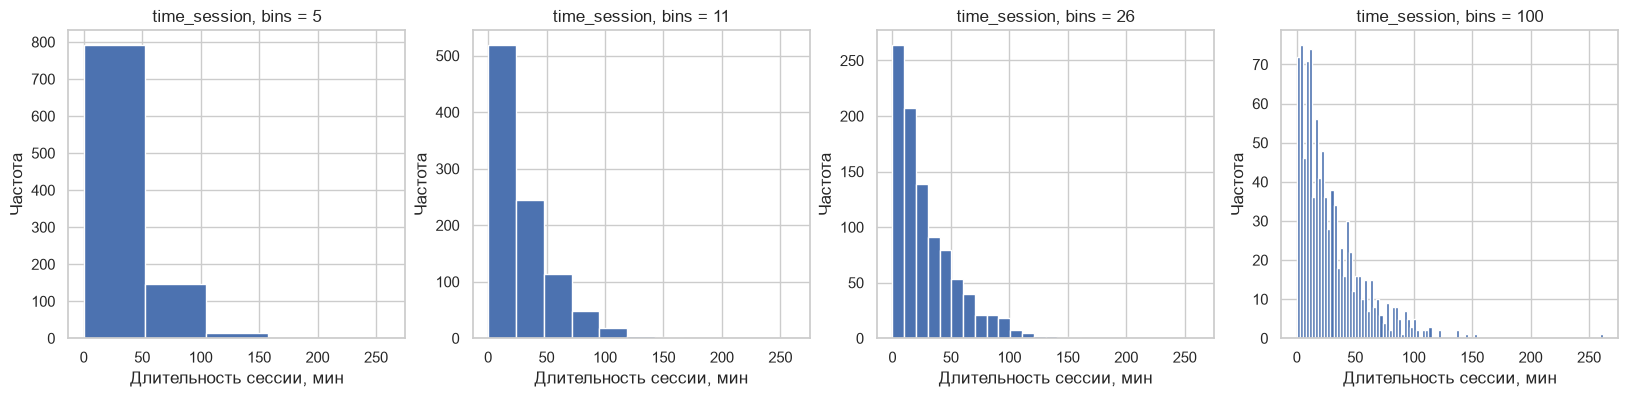

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, b in zip(axes, [5, 11, 26, 100]):
    ax.hist(df['time_session'], bins=b, edgecolor='white')
    ax.set_title(f'time_session, bins = {b}')
    ax.set_xlabel('Длительность сессии, мин')
    ax.set_ylabel('Частота')
plt.show()

При `bins = 5` и `11` форма распределения слишком сглажена, при `bins = 100` гистограмма «рассыпается» на отдельные столбики. Значение около 26 (интервал ≈ 10 минут) показывает и пик в начале, и правый хвост. По тому же принципу – «круглая» ширина интервала, близкая к результату правил Скотта/корня – выбраны значения для остальных признаков:

| Признак | bins | Ширина интервала | Обоснование |
|---|---|---|---|
| `time_session` | 26 | ≈ 10 мин | близко к Скотту (28) |
| `click_count` | 29 | ≈ 3 клика | близко к Скотту (27) |
| `buy_count` | 16 | 1 покупка | дискретный признак: один интервал на каждое целое значение 0…15 |
| `price` | 28 | ≈ 2000 | близко к Скотту (32) |
| `age` | 12 | ≈ 5 лет | близко к Скотту (14), удобно читать по возрастным группам |

#### 3.2 Гистограммы всех числовых признаков

На графики нанесены среднее (красная пунктирная линия) и медиана (зелёная линия). В шестой панели показана стоимость только для сессий с покупками (`price > 0`).

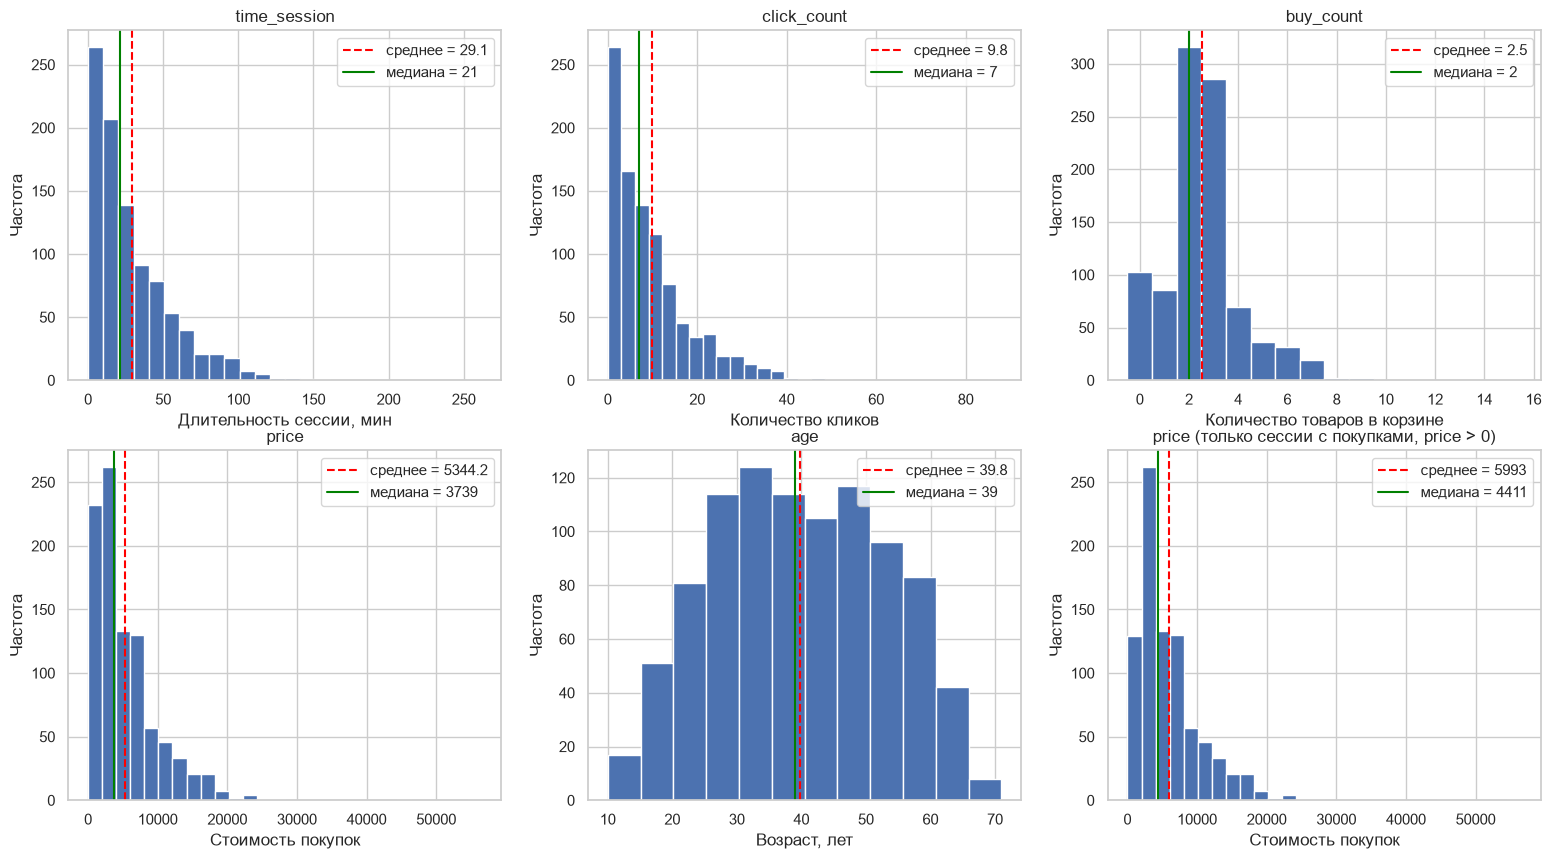

In [27]:
bins_chosen = {'time_session': 26, 'click_count': 29,
               'buy_count': np.arange(-0.5, 16.5, 1), 'price': 28, 'age': 12}
labels = {'time_session': 'Длительность сессии, мин', 'click_count': 'Количество кликов',
          'buy_count': 'Количество товаров в корзине', 'price': 'Стоимость покупок', 'age': 'Возраст, лет'}

fig, axes = plt.subplots(2, 3, figsize=(19, 10))
for ax, c in zip(axes.flat, num_cols):
    ax.hist(df[c], bins=bins_chosen[c], edgecolor='white')
    ax.axvline(df[c].mean(), color='red', linestyle='--', label=f'среднее = {df[c].mean():.1f}')
    ax.axvline(df[c].median(), color='green', linestyle='-', label=f'медиана = {df[c].median():.0f}')
    ax.set_title(c)
    ax.set_xlabel(labels[c])
    ax.set_ylabel('Частота')
    ax.legend()

ax = axes.flat[-1]
buyers = df.loc[df['price'] > 0, 'price']
ax.hist(buyers, bins=28, edgecolor='white')
ax.axvline(buyers.mean(), color='red', linestyle='--', label=f'среднее = {buyers.mean():.0f}')
ax.axvline(buyers.median(), color='green', linestyle='-', label=f'медиана = {buyers.median():.0f}')
ax.set_title('price (только сессии с покупками, price > 0)')
ax.set_xlabel('Стоимость покупок')
ax.set_ylabel('Частота')
ax.legend()
plt.show()

**Выводы по гистограммам:**

- **`time_session`** – сильно скошена вправо (коэффициент асимметрии ≈ 1.9). Мода в первых интервалах (0–10 мин): около 25% сессий не длиннее 9 минут. Среднее (29) выше медианы (21) из-за небольшого числа длинных сессий (до 262 мин).
- **`click_count`** – форма почти такая же, как у длительности: пик у малых значений (0–3 клика) и длинный хвост до 88. Это согласуется с почти функциональной связью этих признаков.
- **`buy_count`** – дискретное распределение: чаще всего 2 (316 сессий) и 3 (286) товара; отдельный столбик в нуле – 103 сессии без покупок (10.8%); значения от 8 и выше – единичные.
- **`price`** – скошена вправо (асимметрия ≈ 2.6), самый «тяжёлый» хвост из всех признаков (максимум 56 546). Первый интервал содержит 103 нулевых значения (сессии без покупок). Среди сессий с покупками (шестая панель) распределение унимодально, с максимумом в районе 2000–4000.
- **`age`** – единственный признак, близкий к симметричному (асимметрия ≈ 0): среднее и медиана практически совпадают (≈ 39–40 лет), основная масса пользователей – 25–55 лет, концы диапазона (10–15 и 65–71 год) малочисленны.

Практический вывод: для скошенных признаков (`time_session`, `click_count`, `price`) в качестве «типичного» значения надёжнее использовать медиану, а не среднее.

### 4. Ковариация и корреляция

**Ковариация** `cov(X, Y)` показывает, изменяются ли два признака в одном направлении (знак «+») или в противоположных (знак «–»). Её величина зависит от единиц измерения признаков (ковариация цены и длительности – порядка 10⁵, а возраста и покупок – порядка 1), поэтому сравнивать ковариации между разными парами нельзя, и можно интерпретировать только знак.

**Коэффициент корреляции Пирсона** – это нормированная ковариация: `r = cov(X, Y) / (σ_X · σ_Y)`. Он безразмерен, лежит в диапазоне от –1 до 1 и измеряет именно **линейную** связь: |r| близко к 1 – связь сильная, близко к 0 – линейной связи нет.

**Коэффициент Спирмена** – корреляция Пирсона, посчитанная по рангам значений. Он измеряет любую **монотонную** связь и менее чувствителен к выбросам.

#### 4.1 Ковариация

In [28]:
df[num_cols].cov().round(1)

,time_session,click_count,buy_count,price,age
time_session,737.8,250.2,41.2,124467.7,-12.8
click_count,250.2,85.0,14.0,42278.0,-4.2
buy_count,41.2,14.0,2.6,7098.4,-0.7
price,124467.7,42278.0,7098.4,25656339.4,-3630.6
age,-12.8,-4.2,-0.7,-3630.6,170.1


Проверим расчёт вручную на паре `time_session` – `click_count` и убедимся, что корреляция действительно равна нормированной ковариации.

In [29]:
x, y = df['time_session'], df['click_count']
cov_manual = ((x - x.mean()) * (y - y.mean())).sum() / (len(df) - 1)

print('Ковариация (вручную):      ', round(cov_manual, 2))
print('Ковариация (pandas):       ', round(x.cov(y), 2))
print('Корреляция = cov / (σx·σy):', round(cov_manual / (x.std() * y.std()), 4))
print('Корреляция (pandas corr):  ', round(x.corr(y), 4))

with_clicks = df[df['click_count'] > 0]
minutes_per_click = with_clicks['time_session'] / with_clicks['click_count']
print('Минут на один клик: среднее =', round(minutes_per_click.mean(), 2), ', стандартное отклонение =', round(minutes_per_click.std(), 2))

Ковариация (вручную):       250.16
Ковариация (pandas):        250.16
Корреляция = cov / (σx·σy): 0.9991
Корреляция (pandas corr):   0.9991
Минут на один клик: среднее = 2.93 , стандартное отклонение = 0.24


#### 4.2 Корреляция Пирсона и Спирмена, тепловые карты

In [30]:
corr_pearson = df[num_cols].corr(method='pearson')
corr_pearson.round(3)

,time_session,click_count,buy_count,price,age
time_session,1.000,0.999,0.947,0.905,-0.036
click_count,0.999,1.000,0.949,0.905,-0.035
buy_count,0.947,0.949,1.000,0.874,-0.035
price,0.905,0.905,0.874,1.000,-0.055
age,-0.036,-0.035,-0.035,-0.055,1.000


In [31]:
corr_spearman = df[num_cols].corr(method='spearman')
corr_spearman.round(3)

,time_session,click_count,buy_count,price,age
time_session,1.000,0.998,0.961,0.962,-0.025
click_count,0.998,1.000,0.962,0.963,-0.023
buy_count,0.961,0.962,1.000,0.931,-0.013
price,0.962,0.963,0.931,1.000,-0.030
age,-0.025,-0.023,-0.013,-0.030,1.000


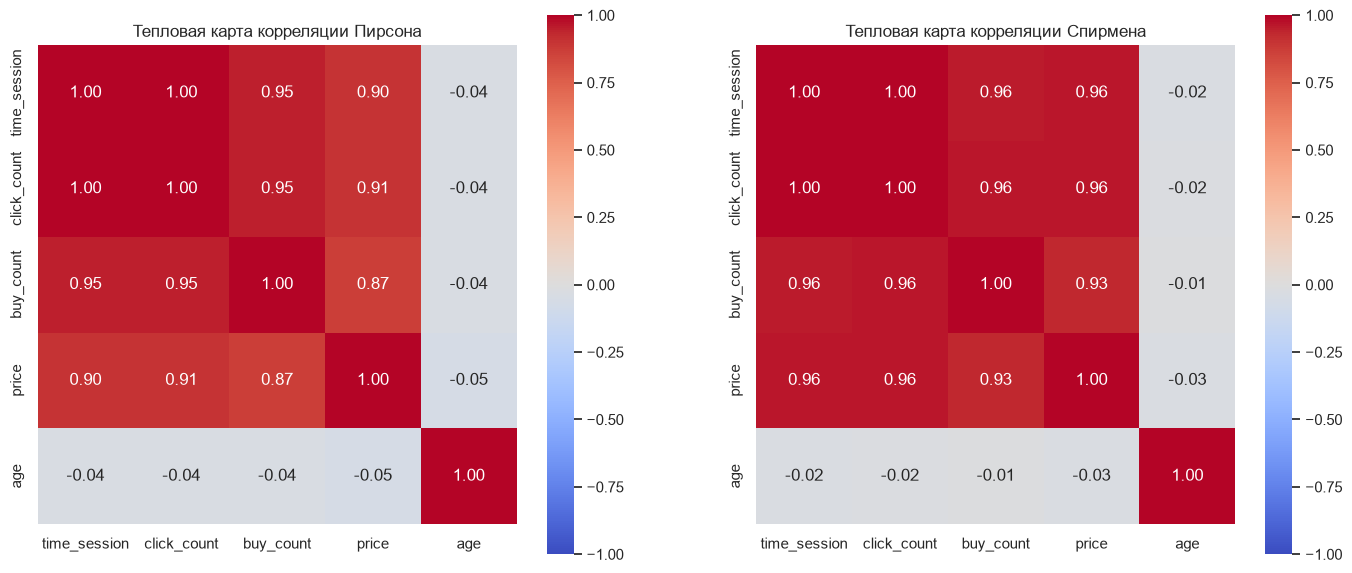

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, (name, cm) in zip(axes, [('Пирсона', corr_pearson), ('Спирмена', corr_spearman)]):
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, ax=ax)
    ax.set_title(f'Тепловая карта корреляции {name}')
plt.show()

Проверим, значима ли слабая корреляция возраста с остальными признаками (нулевая гипотеза: корреляция равна 0; значимой считаем связь при p < 0.05).

In [33]:
for c in ['time_session', 'click_count', 'buy_count', 'price']:
    r, p = stats.pearsonr(df['age'], df[c])
    print(f'age – {c:13s} r = {r:+.3f}, p-value = {p:.3f}')

age – time_session  r = -0.036, p-value = 0.264
age – click_count   r = -0.035, p-value = 0.279
age – buy_count     r = -0.035, p-value = 0.276
age – price         r = -0.055, p-value = 0.090


**Интерпретация:**

1. **Сильная положительная линейная связь** между `time_session`, `click_count`, `buy_count` и `price` – все ковариации положительны, а корреляции Пирсона лежат в диапазоне 0.87–0.999:
   - `time_session` – `click_count`: r = 0.999 – практически функциональная зависимость (≈ 3 минуты на клик);
   - `buy_count` – `time_session` / `click_count`: r ≈ 0.95;
   - `price` – `time_session` / `click_count`: r = 0.905; `price` – `buy_count`: r = 0.874.
2. **Возраст не связан линейно ни с одним признаком:** r от –0.036 до –0.055, ковариации близки к нулю. По критерию значимости ни одна из этих корреляций не отличается от нуля на уровне 5% (p от 0.09 до 0.28). Возраст пользователя не влияет на длительность сессии, число кликов, число и стоимость покупок.
3. **Спирмен выше Пирсона для `price`** (0.93–0.96 против 0.87–0.91). Это означает, что связь стоимости с активностью почти идеально монотонна, а более низкое значение Пирсона вызвано выбросами – единичными сессиями с аномально высокой стоимостью при короткой длительности.
4. **Мультиколлинеарность:** `time_session` и `click_count` почти дублируют друг друга (r = 0.999). Если эти признаки будут использоваться в модели, достаточно оставить один из них.
5. Корреляция показывает **статистическую связь, а не причинность**: например, высокая корреляция «стоимость – длительность» не доказывает, что длинные сессии *вызывают* покупки (возможно, наоборот: пользователи, которые покупают, дольше остаются на сайте).

### 5. Графики по заданию варианта

#### Задание 1

*`Использовать seaborn. По группировке - region и количество клиентов, привлеченных из рекламных источников каждого типа (channel) построить диаграмму следующего вида.`*

In [34]:
grp1 = df.groupby(['region', 'channel']).size().reset_index(name='count')
grp1

,region,channel,count
0,Russia,FaceBoom,8
1,Russia,MediaTornado,4
2,Russia,TipTop,9
3,Russia,organic,31
4,United States,FaceBoom,141
5,United States,MediaTornado,47
6,United States,TipTop,133
7,United States,organic,579


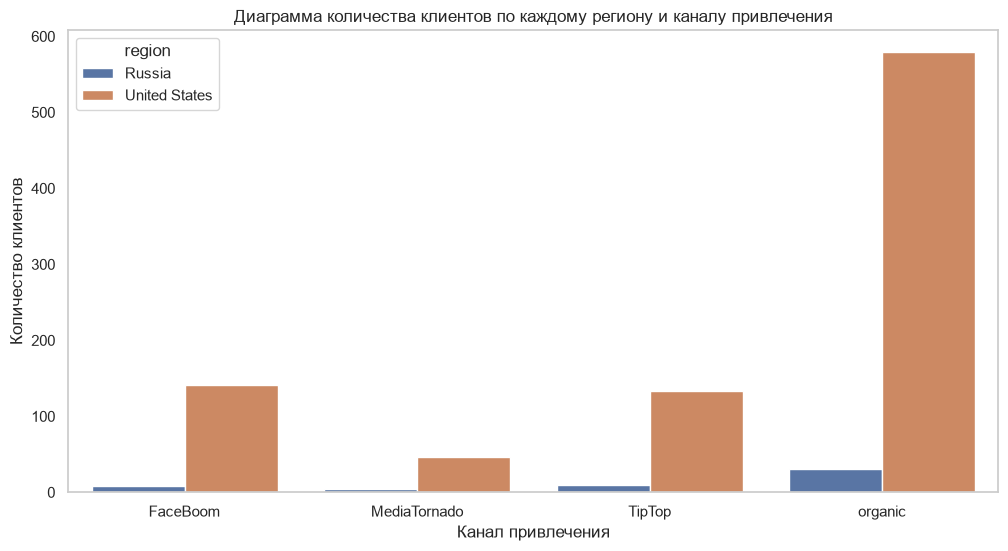

In [35]:
plt.figure(figsize=(12, 6))
sns.barplot(data=grp1, x='channel', y='count', hue='region', order=sorted(df['channel'].unique()))
plt.title('Диаграмма количества клиентов по каждому региону и каналу привлечения')
plt.xlabel('Канал привлечения')
plt.ylabel('Количество клиентов')
plt.grid(axis='y')
plt.show()

В обоих регионах преобладает канал `organic`: в США – 579 записей (около 64% всех сессий страны), в России – 31. Среди рекламных каналов в США лидируют `FaceBoom` (141) и `TipTop` (133), `MediaTornado` приводит заметно меньше (47). В России сессий мало (всего 52), и по рекламным каналам они распределены примерно по 4–9 штук, поэтому сравнивать каналы внутри России ненадёжно. Из-за огромной разницы в объёмах (900 сессий из США против 52 из России) на одном графике абсолютные значения по России почти не видны; для сравнения структуры каналов лучше использовать доли.

#### Задание 2

*`Использовать pandas и plot. По сводной таблице (pivot_table) - отобразить уникальное (nunique) количество пользователей для каждого канала (channel). Оставить только маркеры в виде ◀ синего цвета размером 15.`*

In [36]:
pt2 = df.pivot_table(index='channel', values='user_id', aggfunc='nunique')
pt2

,user_id
channel,
FaceBoom,147
MediaTornado,51
TipTop,139
organic,547


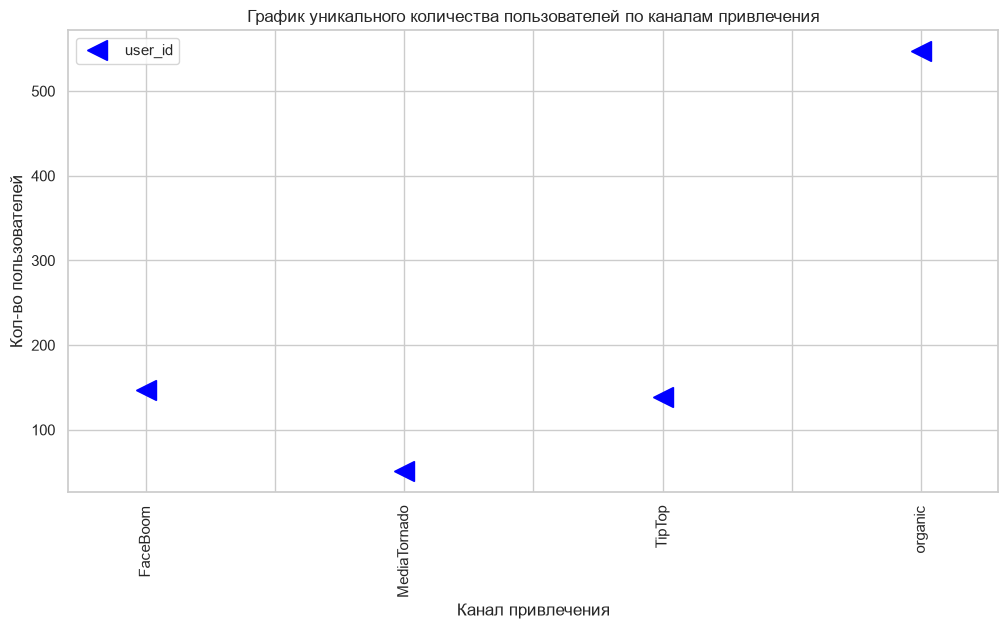

In [37]:
ax = pt2.plot(marker='<', linestyle='none', color='blue', markersize=15,
              figsize=(12, 6), grid=True, rot=90,
              title='График уникального количества пользователей по каналам привлечения')
ax.set_xlabel('Канал привлечения')
ax.set_ylabel('Кол-во пользователей')
ax.margins(x=0.1)
plt.show()

Больше всего уникальных пользователей привлёк `organic` – 547; далее `FaceBoom` – 147, `TipTop` – 139 и `MediaTornado` – 51. Соотношение каналов такое же, как по числу сессий, то есть повторные заходы распределены между каналами равномерно. Сумма по каналам (884) больше общего числа уникальных пользователей (782): 102 пользователя пришли в магазин более чем из одного источника и посчитаны в каждом из них.

#### Задание 3

*`Использовать matplotlib. Построить круговую диаграмму, которая отображает процент каждого устройства (device).`*

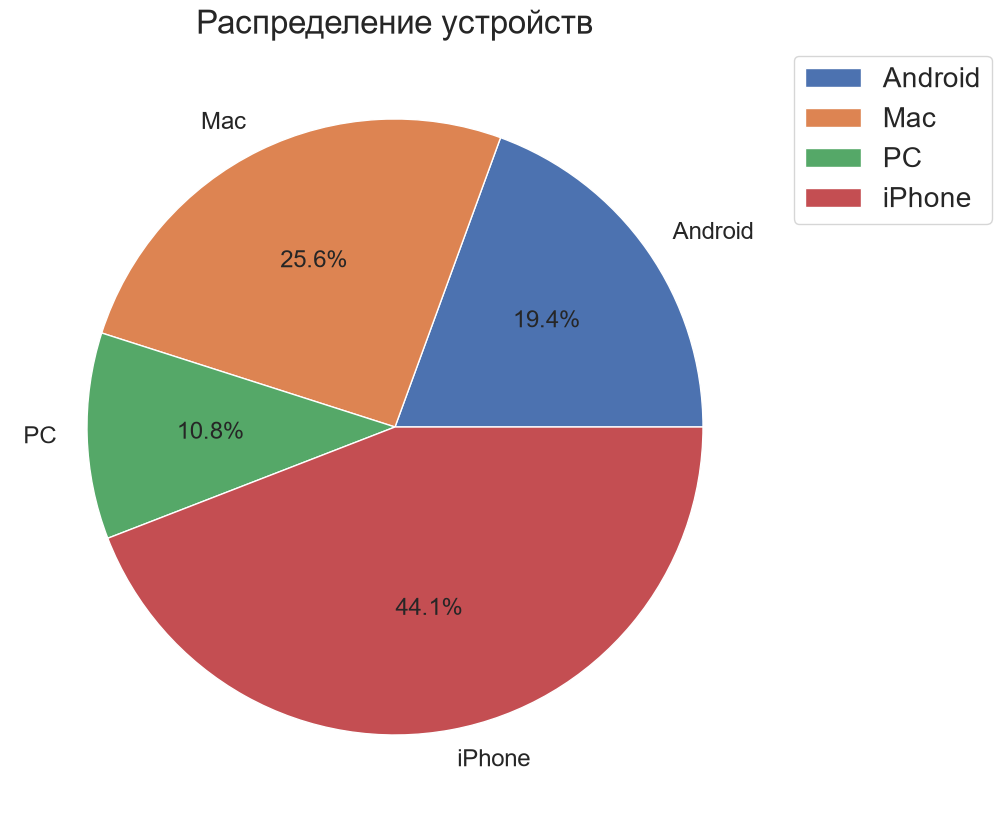

In [38]:
device_counts = df['device'].value_counts().sort_index()

plt.figure(figsize=(20, 10))
plt.pie(device_counts, labels=device_counts.index, autopct='%1.1f%%', textprops={'size': 'x-large'})
plt.title('Распределение устройств', fontsize=24)
plt.legend(fontsize=20, bbox_to_anchor=(1, 1))
plt.show()

Почти половина сессий (44.1%, 420 записей) приходится на iPhone; далее Mac (25.6%), Android (19.4%) и PC (10.8%). Устройства Apple (iPhone + Mac) дают около 70% сессий. Мобильные устройства (iPhone + Android) – около 64%, настольные (Mac + PC) – около 36%, т.е. магазином пользуются преимущественно со смартфонов.

### 6. Hexagonal binning plot

Hexbin разбивает плоскость на шестиугольные ячейки и окрашивает их по числу попавших точек – чем темнее ячейка, тем больше наблюдений. Он удобен, когда точек много и они накладываются друг на друга. Построим два графика: «длительность – стоимость» (где связь есть) и «возраст – стоимость» (где связи нет).

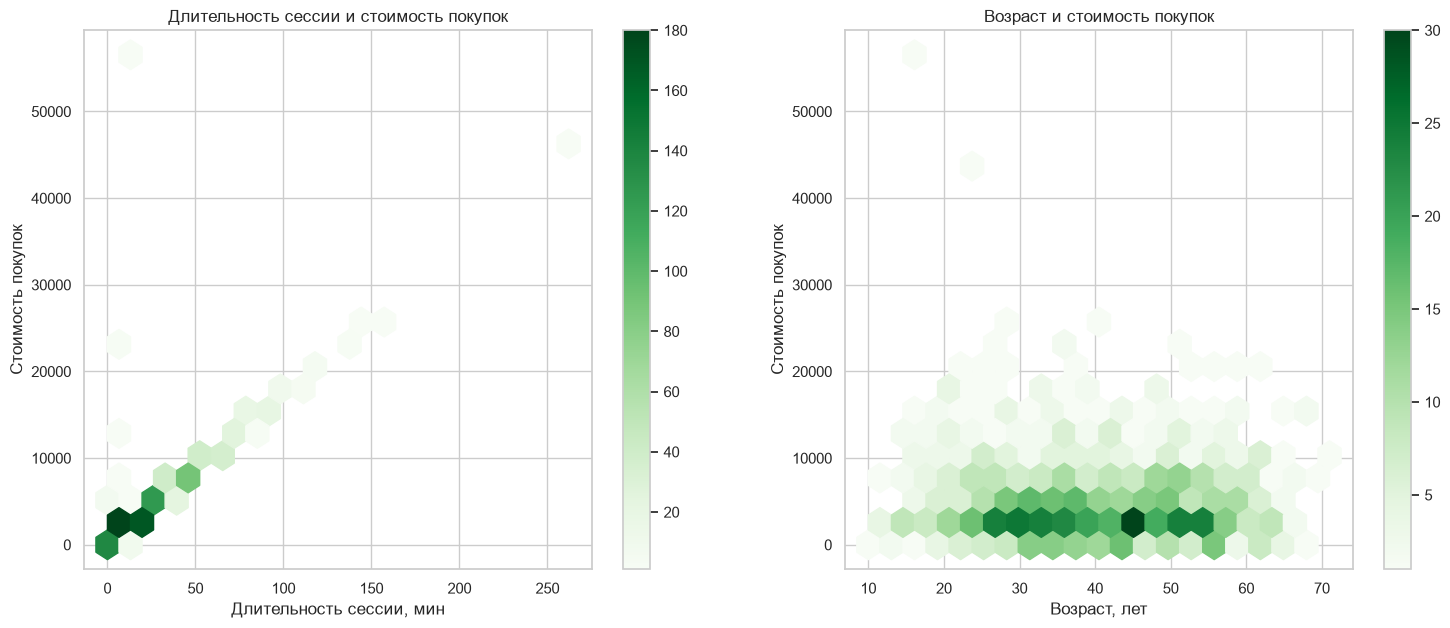

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

df.plot(x='time_session', y='price', kind='hexbin', gridsize=20, cmap='Greens', mincnt=1,
        sharex=False, ax=axes[0], title='Длительность сессии и стоимость покупок')
axes[0].set_xlabel('Длительность сессии, мин')
axes[0].set_ylabel('Стоимость покупок')

df.plot(x='age', y='price', kind='hexbin', gridsize=20, cmap='Greens', mincnt=1,
        sharex=False, ax=axes[1], title='Возраст и стоимость покупок')
axes[1].set_xlabel('Возраст, лет')
axes[1].set_ylabel('Стоимость покупок')
plt.show()

**Выводы по hexbin:**

- **«Длительность – стоимость» (слева).** Самые тёмные ячейки (до 180 сессий в одной ячейке) находятся в левом нижнем углу: основная масса сессий – короткие (до ≈ 25 мин) и недорогие (до ≈ 5000). От этого угла вверх тянется узкая диагональная полоса до ≈ 150 минут и ≈ 25 000: чем дальше, тем светлее ячейки, т.е. длинные и дорогие сессии редки. Узость полосы подтверждает сильную линейную связь (r = 0.905). Отдельно стоят светлые ячейки вне полосы – короткие сессии с аномально высокой стоимостью (≈ 13 000, ≈ 23 000 и ≈ 56 500 при длительности 5–12 минут) и самая длинная сессия (262 мин) в правом верхнем углу.
- **«Возраст – стоимость» (справа).** Плотность образует горизонтальную полосу у низких значений стоимости (до ≈ 5000) для всех возрастов от 25 до 55 лет (до 30 сессий в ячейке). Полоса не наклонена ни вверх, ни вниз: с ростом возраста стоимость в среднем не меняется – связи нет, что согласуется с r ≈ –0.05.
- В отличие от обычной диаграммы рассеяния, hexbin показывает, где именно сосредоточено большинство наблюдений: типичная сессия – короткая и недорогая, а «хвост» дорогих покупок образуют единичные сессии.

### 7. Boxplot для числовых столбцов

Построим «ящики с усами» (matplotlib) для всех числовых признаков. Для каждого признака используется собственная шкала, т.к. единицы измерения различаются. «Усы» простираются до 1.5 межквартильных размахов (IQR) от квартилей, всё, что за их пределами, показано точками как выбросы.

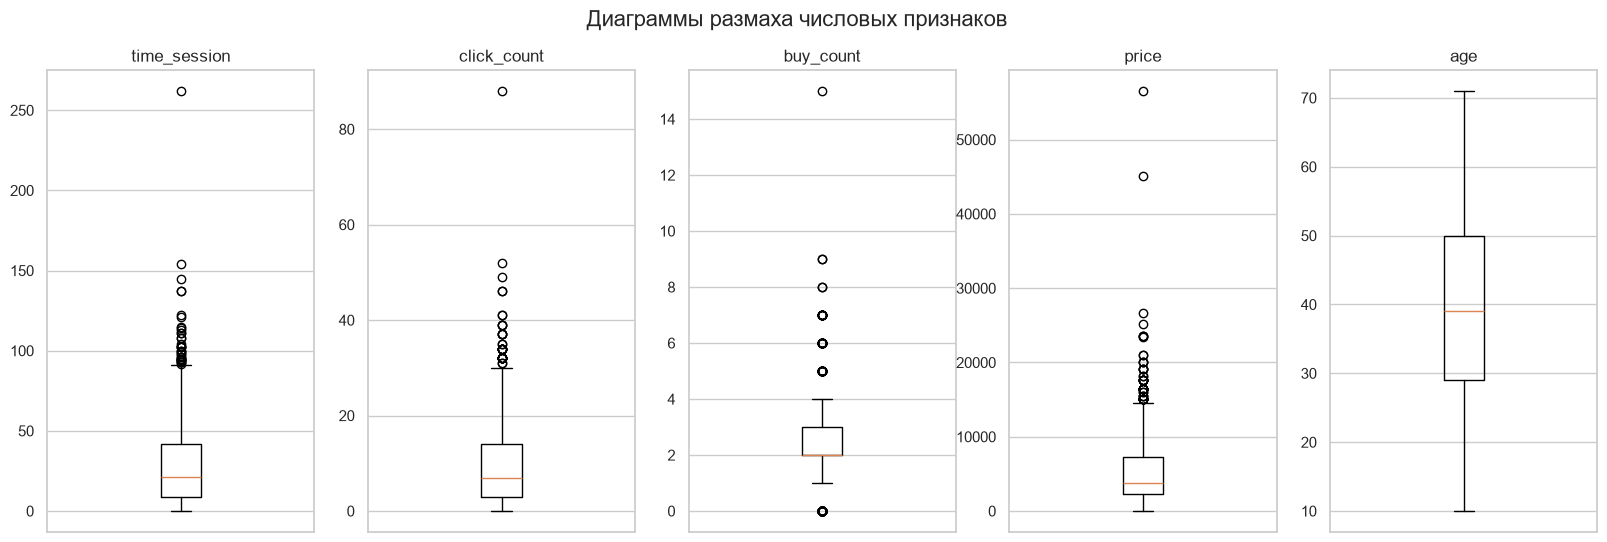

In [40]:
fig, axes = plt.subplots(1, 5, figsize=(20, 6))
for ax, c in zip(axes, num_cols):
    ax.boxplot(df[c])
    ax.set_title(c)
    ax.set_xticks([])
plt.suptitle('Диаграммы размаха числовых признаков', fontsize=16)
plt.show()

Рассчитаем границы «усов» и число выбросов по правилу 1.5·IQR.

In [41]:
rows = {}
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows[c] = {'Q1': q1, 'медиана': df[c].median(), 'Q3': q3, 'IQR': iqr,
               'нижняя граница': low, 'верхняя граница': high,
               'максимум': df[c].max(), 'выбросов': int(((df[c] < low) | (df[c] > high)).sum())}
pd.DataFrame(rows).T

,Q1,медиана,Q3,IQR,нижняя граница,верхняя граница,максимум,выбросов
time_session,9.0,21.0,42.0,33.0,-40.5,91.5,262.0,36.0
click_count,3.0,7.0,14.0,11.0,-13.5,30.5,88.0,37.0
buy_count,2.0,2.0,3.0,1.0,0.5,4.5,15.0,195.0
price,2301.0,3739.0,7284.0,4983.0,-5173.5,14758.5,56546.0,53.0
age,29.0,39.0,50.0,21.0,-2.5,81.5,71.0,0.0


**Выводы по boxplot:**

- **`time_session`**: медиана 21 мин, «ящик» 9–42 мин, верхняя граница усов 91.5 мин; 36 выбросов (3.8% сессий) вплоть до 262 мин. Нижних выбросов нет (нижняя граница отрицательна).
- **`click_count`**: медиана 7, «ящик» 3–14, верхняя граница 30.5; 37 выбросов, максимум 88. Картина повторяет `time_session`.
- **`price`**: медиана 3739, «ящик» 2301–7284, верхняя граница 14 758; 53 выброса (5.6%). Два значения заметно оторваны от остальных – 45 046 и 56 546 (следующее по величине – 26 644).
- **`buy_count`**: медиана 2, «ящик» 2–3, IQR = 1, поэтому границы усов очень узкие (0.5–4.5) и «выбросами» оказались 195 значений – это 103 сессии без покупок и 92 сессии с 5 и более товарами. Для дискретного признака с узким IQR это не аномалии, а обычные значения; по-настоящему выделяется только 15 товаров.
- **`age`**: медиана 39, «ящик» 29–50, усы охватывают весь диапазон 10–71 год, выбросов нет – распределение симметричное и «чистое».

Признаки со скошенными распределениями (`time_session`, `click_count`, `price`) имеют длинный верхний ус и выбросы только сверху, что согласуется с гистограммами. Большинство этих выбросов – «естественные» (очень долгие сессии с большим числом кликов и покупок лежат на общей линии связи), поэтому их удалять не нужно. Проверки требуют только короткие сессии с непропорционально высокой стоимостью (в т.ч. 56 546 при одной покупке и 7 минутах).

### 8. Категоризация числового столбца и boxplot по категориям

Создадим категориальный столбец `dur_category` по длительности сессии. Границы выбраны по квартилям из таблицы выше (Q1 = 9, медиана = 21, Q3 = 42 мин) и совпадают с границами, использованными в первой лабораторной работе:
- **низкая** – до 9 минут включительно (≈ нижняя четверть сессий);
- **средняя** – от 10 до 45 минут;
- **высокая** – более 45 минут (≈ верхняя четверть сессий).

In [42]:
df['dur_category'] = pd.cut(df['time_session'], bins=[-1, 9, 45, np.inf],
                            labels=['низкая', 'средняя', 'высокая'])
df['dur_category'].value_counts()

dur_category
средняя    507
низкая     243
высокая    202
Name: count, dtype: int64

Распределение по категориям: 507 сессий (53%) – средней длительности, 243 (26%) – низкой, 202 (21%) – высокой. Группы достаточно крупные, чтобы сравнивать их между собой.

Построим boxplot (seaborn) для `time_session` по новым категориям, как требует задание, а также для `price` – чтобы увидеть, как меняется стоимость покупок с ростом длительности.

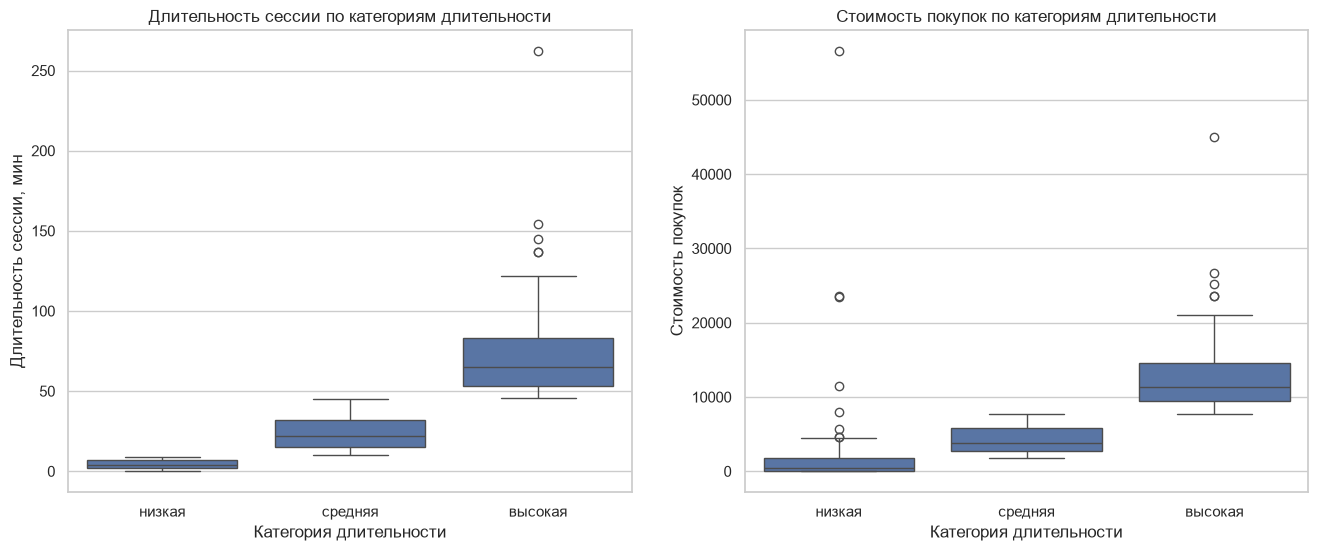

In [43]:
order = ['низкая', 'средняя', 'высокая']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=df, x='dur_category', y='time_session', order=order, ax=axes[0])
axes[0].set_title('Длительность сессии по категориям длительности')
axes[0].set_xlabel('Категория длительности')
axes[0].set_ylabel('Длительность сессии, мин')

sns.boxplot(data=df, x='dur_category', y='price', order=order, ax=axes[1])
axes[1].set_title('Стоимость покупок по категориям длительности')
axes[1].set_xlabel('Категория длительности')
axes[1].set_ylabel('Стоимость покупок')
plt.show()

In [44]:
df.groupby('dur_category', observed=True)[['time_session', 'click_count', 'buy_count', 'price']].median()

,time_session,click_count,buy_count,price
dur_category,,,,
низкая,4.0,2.0,1.0,453.0
средняя,22.0,7.0,2.0,3739.0
высокая,65.0,22.0,4.0,11310.0


Кроме того, проверим, насколько стабильно стоимость покупок «привязана» к длительности: рассчитаем стоимость на одну минуту сессии (для сессий от 10 минут, чтобы исключить деление на очень малые значения).

In [45]:
long_sessions = df[df['time_session'] >= 10]
(long_sessions['price'] / long_sessions['time_session']).describe().round(1)

count    709.0
mean     181.8
std       11.3
min      163.6
25%      174.0
50%      179.0
75%      187.0
max      213.9
dtype: float64

**Выводы по boxplot с категориями длительности:**

- **Длительность сессии (слева).** Ящики категорий не пересекаются: медианы 4, 22 и 65 минут. Поскольку категории построены по самому столбцу `time_session`, график в основном показывает разброс внутри категорий: низкая и средняя категории компактны (ограничены порогами 9 и 45 минут), а высокая – самая «растянутая» – её правый хвост доходит до 262 минут с выбросами 137–154 мин.
- **Стоимость покупок (справа).** Медиана стоимости растёт вместе с категорией длительности: 453 → 3739 → 11 310. Ящики средней и высокой категорий не пересекаются, т.е. долгие сессии приносят многократно большую стоимость. Средняя категория очень компактна, что объясняется почти постоянной «стоимостью минуты» – в сессиях от 10 минут она составляет в среднем ≈ 182 ед. при стандартном отклонении ≈ 11 (см. таблицу выше). В низкой категории ящик расположен у нуля (много сессий без покупок), но видны выбросы 11–56 тыс. – это те самые короткие сессии с аномально высокой стоимостью.

### 9. Boxplot по другим категориям (разные библиотеки)

#### 9.1 matplotlib: длительность сессии по рекламным каналам

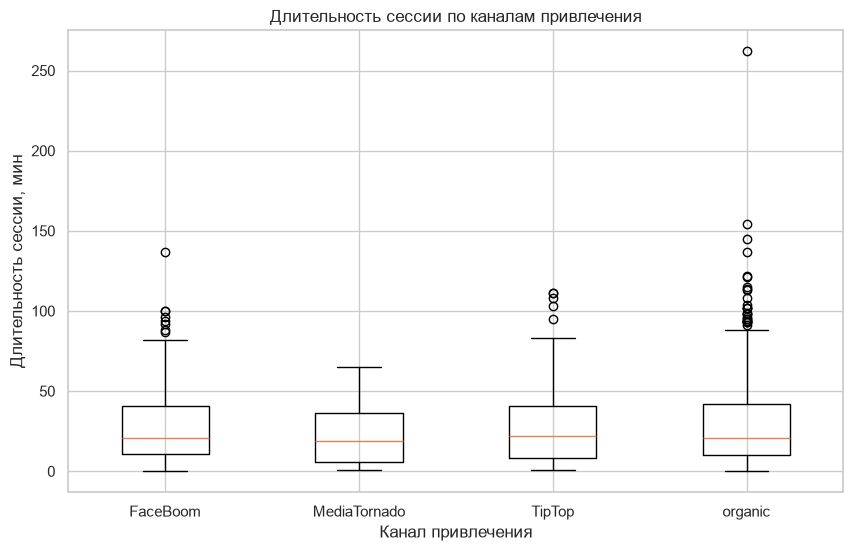

In [46]:
channels = sorted(df['channel'].unique())
data = [df.loc[df['channel'] == ch, 'time_session'] for ch in channels]

plt.figure(figsize=(10, 6))
plt.boxplot(data)
plt.xticks(range(1, len(channels) + 1), channels)
plt.title('Длительность сессии по каналам привлечения')
plt.xlabel('Канал привлечения')
plt.ylabel('Длительность сессии, мин')
plt.show()

#### 9.2 pandas: стоимость покупок по устройствам

Для корректного сравнения берём только сессии с покупками (`price > 0`): нулевая стоимость означает отсутствие покупки и «сдвигает» все распределения вниз одинаково.

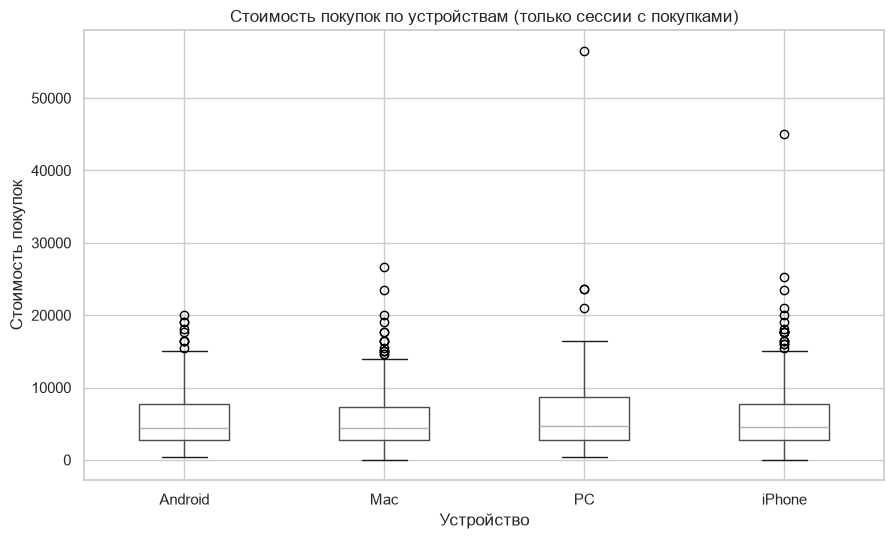

In [47]:
ax = df[df['price'] > 0].boxplot(column='price', by='device', figsize=(10, 6))
plt.suptitle('')
ax.set_title('Стоимость покупок по устройствам (только сессии с покупками)')
ax.set_xlabel('Устройство')
ax.set_ylabel('Стоимость покупок')
plt.show()

#### 9.3 seaborn: длительность сессии по странам и возраст по каналам

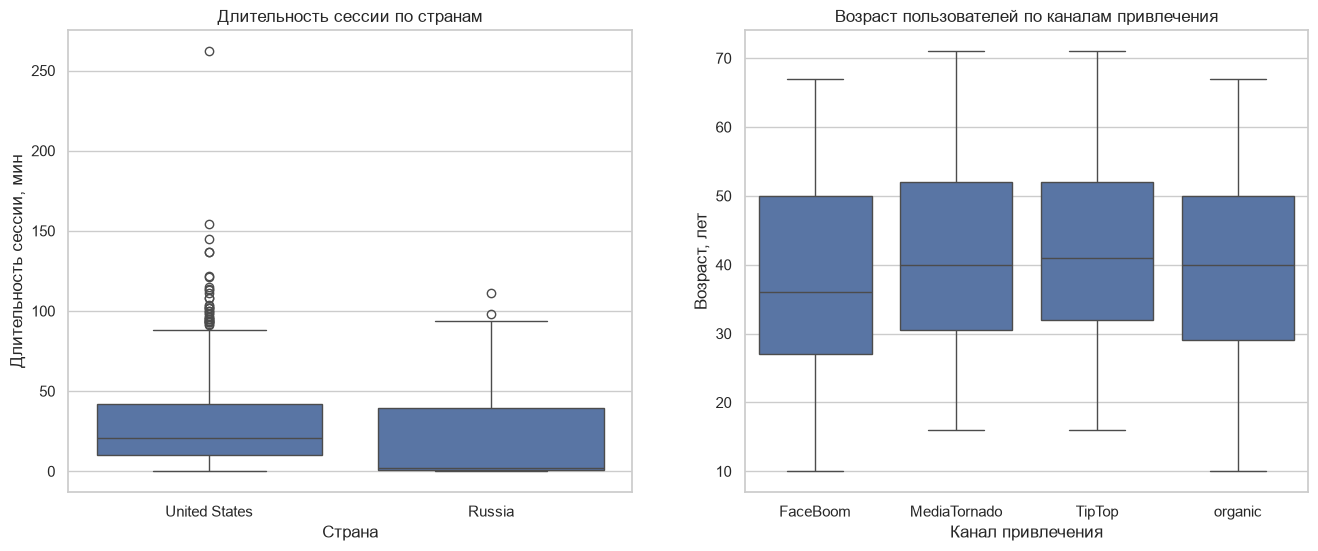

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=df, x='region', y='time_session', ax=axes[0])
axes[0].set_title('Длительность сессии по странам')
axes[0].set_xlabel('Страна')
axes[0].set_ylabel('Длительность сессии, мин')

sns.boxplot(data=df, x='channel', y='age', order=channels, ax=axes[1])
axes[1].set_title('Возраст пользователей по каналам привлечения')
axes[1].set_xlabel('Канал привлечения')
axes[1].set_ylabel('Возраст, лет')
plt.show()

Чтобы не делать выводы только «на глаз», проверим различия между группами непараметрическими критериями (распределения сильно скошены, поэтому t-тест и ANOVA не подходят): Краскела–Уоллиса для 3 и более групп и Манна–Уитни для двух. Различия считаем значимыми при p < 0.05.

In [49]:
def groups(frame, by, col):
    return [g[col] for _, g in frame.groupby(by)]

print('Длительность по каналам  (Краскел–Уоллис): p =', round(stats.kruskal(*groups(df, 'channel', 'time_session')).pvalue, 3))
print('Стоимость по устройствам (Краскел–Уоллис): p =', round(stats.kruskal(*groups(df[df['price'] > 0], 'device', 'price')).pvalue, 3))
print('Возраст по каналам       (Краскел–Уоллис): p =', round(stats.kruskal(*groups(df, 'channel', 'age')).pvalue, 3))
u = stats.mannwhitneyu(df.loc[df['region'] == 'Russia', 'time_session'],
                       df.loc[df['region'] == 'United States', 'time_session'])
print('Длительность по странам  (Манн–Уитни):     p =', round(u.pvalue, 4))

print()
print('Доля сессий без покупок по странам, %:')
print((df.groupby('region')['buy_count'].apply(lambda s: (s == 0).mean()) * 100).round(1))

Длительность по каналам  (Краскел–Уоллис): p = 0.486
Стоимость по устройствам (Краскел–Уоллис): p = 0.534
Возраст по каналам       (Краскел–Уоллис): p = 0.095
Длительность по странам  (Манн–Уитни):     p = 0.0006

Доля сессий без покупок по странам, %:
region
Russia           51.9
United States     8.4
Name: buy_count, dtype: float64


**Выводы по boxplot по категориям:**

- **Длительность по каналам (matplotlib).** Медианы почти одинаковы: 21 (FaceBoom), 19 (MediaTornado), 22 (TipTop) и 21 мин (organic); ящики имеют близкую ширину (нижний квартиль 5–11 мин, верхний 36–42 мин). По критерию Краскела–Уоллиса различия незначимы (p = 0.49). Больше всего выбросов и самое экстремальное значение (262 мин) у `organic` – просто потому, что в нём больше всего сессий (610); у `MediaTornado` (51 сессия) усы короче из-за малой выборки.
- **Стоимость по устройствам, только покупки (pandas).** Медианы практически совпадают: 4411 (Android, Mac), 4546 (iPhone), 4650 (PC); различия незначимы (p = 0.53). У PC чуть шире «ящик» и выше верхний ус из-за единичного выброса 56 546, поэтому среднее для PC (≈ 6989) выше, чем для остальных устройств (≈ 5600–6000), но типичная сумма покупки такая же.
- **Длительность по странам (seaborn).** Различие значимо (Манн–Уитни, p < 0.001): медиана длительности в США – 21 мин, в России – 2 мин. Верхняя часть «ящика» (≈ 39 мин против 42) почти одинакова, т.е. российские сессии как бы делятся на две группы: примерно половина – почти мгновенные заходы и 51.9% всех российских сессий не содержат покупок (в США – 8.4%), остальные близки по поведению к американским. Размер выборки по России небольшой (52 сессии), поэтому вывод нужно считать предварительным; причины (нецелевой трафик, особенности рекламы) по этим данным установить нельзя.
- **Возраст по каналам (seaborn).** Медиана возраста у `FaceBoom` – 36 лет, у остальных каналов – 40–41 год: аудитория FaceBoom моложе примерно на 4–5 лет. Однако критерий Краскела–Уоллиса не подтверждает значимость различия на уровне 5% (p = 0.095), поэтому это лишь тенденция, требующая большего объёма данных.

**Общий вывод:** тип устройства и рекламный канал практически не влияют на длительность сессии и стоимость покупок; единственное статистически значимое различие – по стране (сессии из России короче и чаще заканчиваются без покупок).

### 10. Общие выводы

**Данные и предобработка.** Исследован набор `visits.csv` – 954 записи о пользовательских сессиях интернет-магазина за 1–4 мая 2019 г. (11 признаков: страна, устройство, рекламный канал, время начала и конца сессии, длительность, клики, количество товаров, стоимость покупок, возраст). При предобработке удалены 2 записи с пропусками (`region`, `device`), убран лишний пробел в названии `user_id`, устранены неявные дубликаты (`USA`/`United States`, `MAC`/`Mac`, `IPHONE`/`iPhone`), числовые столбцы приведены к `int64`, даты преобразованы в `datetime` с явным форматом «день.месяц» (проверено совпадением с `time_session`). Итог – 952 сессии и 782 уникальных пользователя; данные согласованы (`price = 0` ровно в сессиях с `buy_count = 0`).

**Распределения.** `time_session`, `click_count` и `price` скошены вправо (медианы 21 мин, 7 кликов и 3739 против средних 29, 9.8 и 5342), поэтому для описания типичного значения корректнее использовать медиану. `buy_count` дискретен (чаще всего 2–3 товара), 10.8% сессий (103) закончились без покупок. `age` распределён симметрично (медиана 39 лет).

**Связи между признаками.** Длительность, число кликов, число товаров и стоимость связаны сильной положительной линейной зависимостью (r = 0.87–0.999): в среднем 1 клик приходится на ≈ 3 минуты, а стоимость составляет ≈ 180 ед. за минуту сессии. `time_session` и `click_count` почти дублируют друг друга (r = 0.999). Возраст не связан ни с одним признаком (|r| ≤ 0.055, p > 0.05). Корреляция отражает статистическую связь, но не причинность.

**Выбросы.** По правилу 1.5·IQR найдено 36 выбросов по длительности, 37 – по кликам, 53 – по стоимости. Большинство из них – естественно долгие и крупные сессии, лежащие на общей линии связи. Проверки требуют несколько коротких сессий (4–7 мин) с непропорционально высокой стоимостью, в т.ч. 56 546 при одной покупке.

**Группы.** Устройства и каналы привлечения не различаются по длительности сессии и стоимости покупок (Краскел–Уоллис, p > 0.09). Значимо отличаются только страны: в России медианная сессия длится 2 мин против 21 в США, а 51.9% сессий заканчиваются без покупок (в США – 8.4%).

**Результаты по заданиям варианта.** Основной источник трафика – `organic` (64.1% сессий, 547 уникальных пользователей); среди рекламных каналов лидируют FaceBoom (15.7%) и TipTop (14.9%), MediaTornado – 5.4%. Структура устройств: iPhone 44.1%, Mac 25.6%, Android 19.4%, PC 10.8%, т.е. около 64% сессий приходится на смартфоны.

**Ограничения.** Данные охватывают только 4 дня; 94.5% сессий относятся к США (выводы по России основаны на 52 сессиях); часть пользователей представлена несколькими сессиями, поэтому наблюдения не полностью независимы.